In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

# Aqui cargamos el archivo desde Drive
df = pd.read_csv('/content/drive/MyDrive/denuncias_policiales.csv', encoding='latin-1', sep=',')

# 1. Ver las dimensiones exactas (Filas y Columnas)
print("Dimensiones del dataset:", df.shape)

# 2. Ver el tipo de datos y si hay nulos
print("\nInformación general de las columnas:")
df.info()

# 3. Ver las primeras 5 filas
display(df.head())

# 4. Ver los tipos de delitos usando la columna correcta
print("\nDistribución de la variable objetivo (Tipos de delitos):")
print(df['P_MODALIDADES'].value_counts())

Dimensiones del dataset: (369100, 8)

Información general de las columnas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 369100 entries, 0 to 369099
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   ANIO            369100 non-null  int64 
 1   MES             369100 non-null  int64 
 2   DPTO_HECHO_NEW  369100 non-null  object
 3   PROV_HECHO      369100 non-null  object
 4   DIST_HECHO      369100 non-null  object
 5   UBIGEO_HECHO    369100 non-null  int64 
 6   P_MODALIDADES   369100 non-null  object
 7   cantidad        369100 non-null  int64 
dtypes: int64(4), object(4)
memory usage: 22.5+ MB


,ANIO,MES,DPTO_HECHO_NEW,PROV_HECHO,DIST_HECHO,UBIGEO_HECHO,P_MODALIDADES,cantidad
0,2018,1,AMAZONAS,BAGUA,ARAMANGO,10202,Otros,4
1,2018,1,AMAZONAS,BAGUA,ARAMANGO,10202,Violencia contra la mujer e integrantes,3
2,2018,1,AMAZONAS,BAGUA,BAGUA,10201,Estafa,2
3,2018,1,AMAZONAS,BAGUA,BAGUA,10201,Hurto,25
4,2018,1,AMAZONAS,BAGUA,BAGUA,10201,Otros,52



Distribución de la variable objetivo (Tipos de delitos):
P_MODALIDADES
Otros                                      107429
Violencia contra la mujer e integrantes     94941
Hurto                                       67438
Robo                                        41751
Estafa                                      31004
ExtorsiÃ³n                                  19527
Secuestro                                    7010
Name: count, dtype: int64


In [ ]:
# Evaluar Completitud (Nulos) y Unicidad (Duplicados)
total_nulos = df.isnull().sum().sum()
total_duplicados = df.duplicated().sum()

print(f"Total de valores faltantes (Nulos): {total_nulos}")
print(f"Total de registros duplicados: {total_duplicados}")

# Aqui si es que hay duplicados, los eliminamos para tener los datos limpios
if total_duplicados > 0:
    df = df.drop_duplicates()
    print(f"Se eliminaron los duplicados. Nuevo tamaño del dataset: {df.shape[0]} registros.")

Total de valores faltantes (Nulos): 0
Total de registros duplicados: 0


/tmp/ipykernel_943/1530031650.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  grafico_modalidades = sns.barplot(


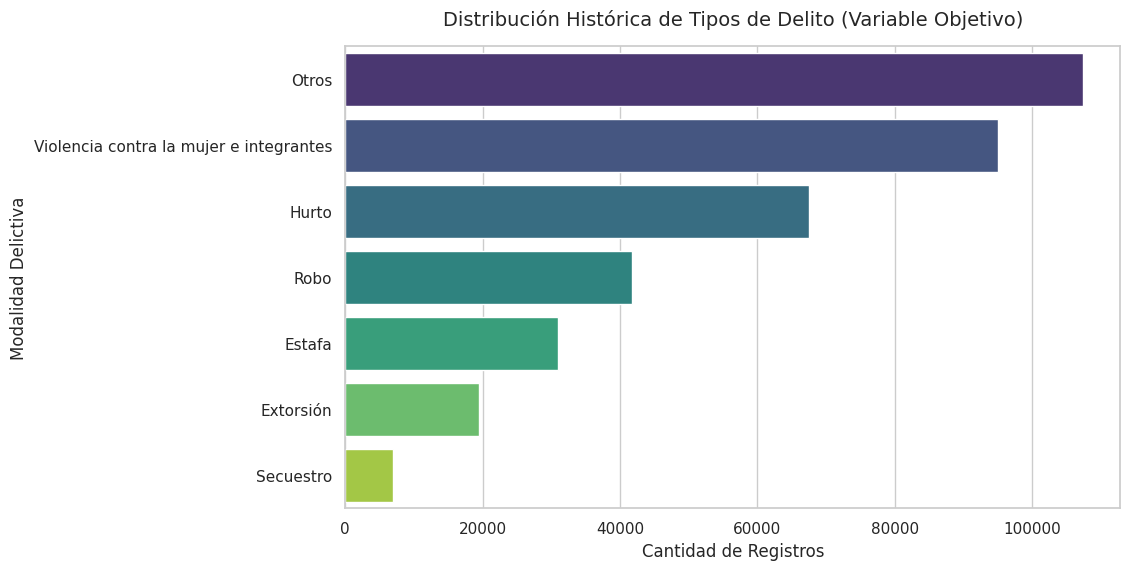

/tmp/ipykernel_943/1530031650.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


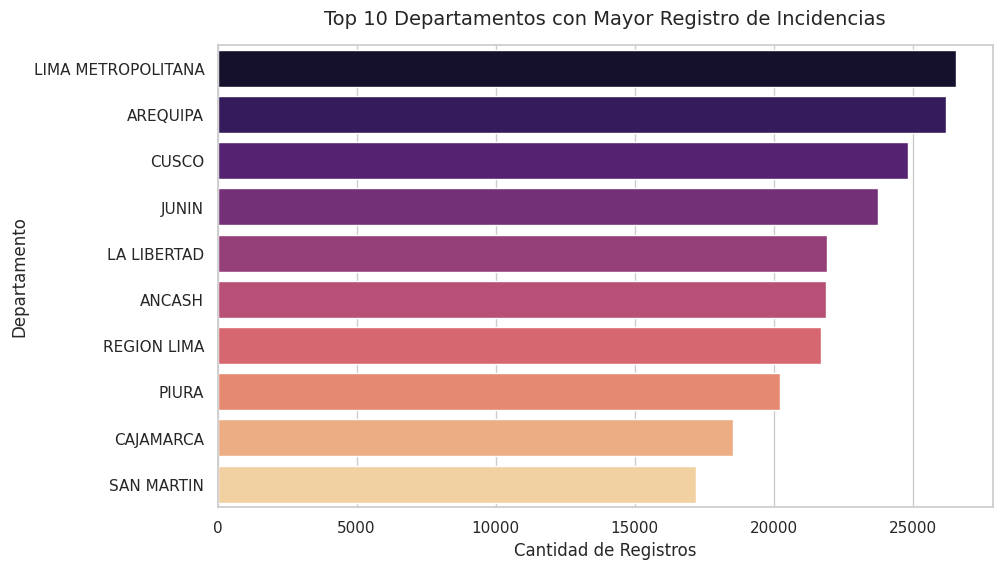

/tmp/ipykernel_943/1530031650.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


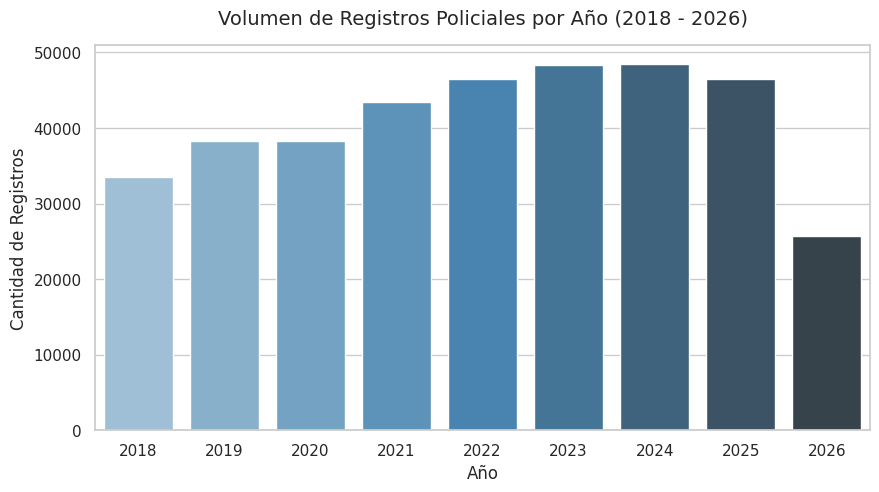

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aca se hace la impieza de caracteres extraños en la variable objetivo
df['P_MODALIDADES'] = df['P_MODALIDADES'].replace('ExtorsiÃ³n', 'Extorsión')

# Configuración de estilo visual para los gráficos
sns.set_theme(style="whitegrid")

# 2. GRÁFICO 1: Distribución de la variable objetivo (Tipos de Delito)
plt.figure(figsize=(10, 6))
grafico_modalidades = sns.barplot(
    y=df['P_MODALIDADES'].value_counts().index,
    x=df['P_MODALIDADES'].value_counts().values,
    palette="viridis"
)
plt.title('Distribución Histórica de Tipos de Delito (Variable Objetivo)', fontsize=14, pad=15)
plt.xlabel('Cantidad de Registros', fontsize=12)
plt.ylabel('Modalidad Delictiva', fontsize=12)
plt.show()

# 3. GRÁFICO 2: Top 10 Departamentos con más registros de denuncias
plt.figure(figsize=(10, 6))
top_dptos = df['DPTO_HECHO_NEW'].value_counts().head(10)
sns.barplot(
    y=top_dptos.index,
    x=top_dptos.values,
    palette="magma"
)
plt.title('Top 10 Departamentos con Mayor Registro de Incidencias', fontsize=14, pad=15)
plt.xlabel('Cantidad de Registros', fontsize=12)
plt.ylabel('Departamento', fontsize=12)
plt.show()

# 4. GRÁFICO 3: Evolución de registros por Año
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x='ANIO',
    palette="Blues_d"
)
plt.title('Volumen de Registros Policiales por Año (2018 - 2026)', fontsize=14, pad=15)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Cantidad de Registros', fontsize=12)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, f1_score

print("Iniciando Pipeline de Datos y Modelado...\n")

# 1. PREPARACIÓN E INGENIERÍA DE DATOS
df_ml = df.copy()
le_dpto, le_prov, le_dist, le_target = LabelEncoder(), LabelEncoder(), LabelEncoder(), LabelEncoder()

df_ml['DPTO_HECHO_NEW'] = le_dpto.fit_transform(df_ml['DPTO_HECHO_NEW'])
df_ml['PROV_HECHO'] = le_prov.fit_transform(df_ml['PROV_HECHO'])
df_ml['DIST_HECHO'] = le_dist.fit_transform(df_ml['DIST_HECHO'])
df_ml['P_MODALIDADES'] = le_target.fit_transform(df_ml['P_MODALIDADES'])

# Eliminar 'cantidad' para evitar Data Leakage
X = df_ml.drop(columns=['P_MODALIDADES', 'cantidad'])
y = df_ml['P_MODALIDADES']

# Train/Test Split (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Escalamiento
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. MODELO BASE (BASELINE) - Regresión Logística
print(" Entrenando Modelo Base (Regresión Logística) ")
# Usamos class_weight='balanced' para ayudar con el desbalance de los delitos
modelo_base = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
modelo_base.fit(X_train_scaled, y_train)
y_pred_base = modelo_base.predict(X_test_scaled)
print("F1-Score (Macro) Baseline:", f1_score(y_test, y_pred_base, average='macro'))

# 3. MODELO AVANZADO - KNN (K=1)
print("\n Entrenando Modelo Avanzado (KNN)")
# Usamos K=1 porque demostró ser el óptimo para evitar sesgos
knn_optimo = KNeighborsClassifier(n_neighbors=1)
knn_optimo.fit(X_train_scaled, y_train)
y_pred_knn = knn_optimo.predict(X_test_scaled)
print("F1-Score (Macro) KNN:", f1_score(y_test, y_pred_knn, average='macro'))

print("\n Modelos entrenados con éxito.")

Iniciando Pipeline de Datos y Modelado...

 Entrenando Modelo Base (Regresión Logística) 
F1-Score (Macro) Baseline: 0.130676790215748

 Entrenando Modelo Avanzado (KNN)
F1-Score (Macro) KNN: 0.02444177345431651

 Modelos entrenados con éxito.


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import pandas as pd

print(" Entrenando Modelo Avanzado 2 (Random Forest) ")
# Usamos n_estimators=50 para que sea rápido y class_weight='balanced' para el desbalance
rf_modelo = RandomForestClassifier(n_estimators=50, random_state=42, class_weight='balanced', n_jobs=-1)
rf_modelo.fit(X_train_scaled, y_train)
y_pred_rf = rf_modelo.predict(X_test_scaled)
f1_rf = f1_score(y_test, y_pred_rf, average='macro')

print("F1-Score (Macro) Random Forest:", f1_rf)

print("\n Generando Tabla Comparativa Final ")
# Creamos la tabla de resultados
resultados = {
    'Modelo': ['Regresión Logística (Baseline)', 'K-Nearest Neighbors (K=1)', 'Random Forest (Tuned)'],
    'F1-Score (Macro)': [0.1306, 0.0244, f1_rf]
}
df_resultados = pd.DataFrame(resultados)
display(df_resultados)

 Entrenando Modelo Avanzado 2 (Random Forest) 
F1-Score (Macro) Random Forest: 0.03705296105391218

 Generando Tabla Comparativa Final 


,Modelo,F1-Score (Macro)
0,Regresión Logística (Baseline),0.130600
1,K-Nearest Neighbors (K=1),0.024400
2,Random Forest (Tuned),0.037053


 Generando Gráficos 


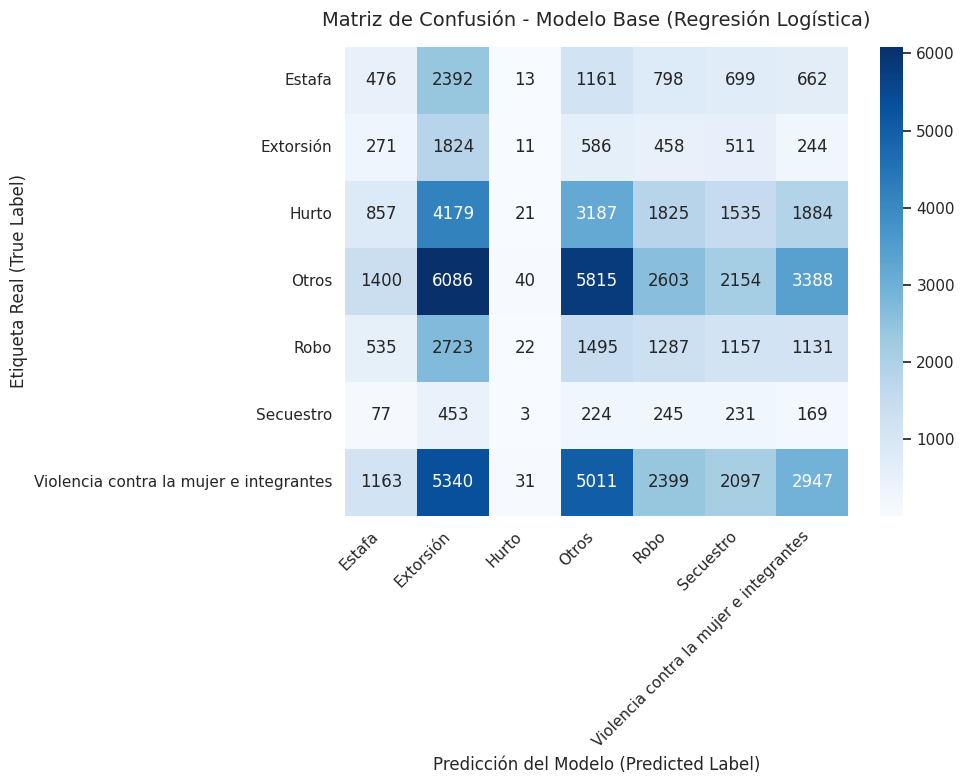

/tmp/ipykernel_943/3459101180.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=features[indices], palette='viridis')


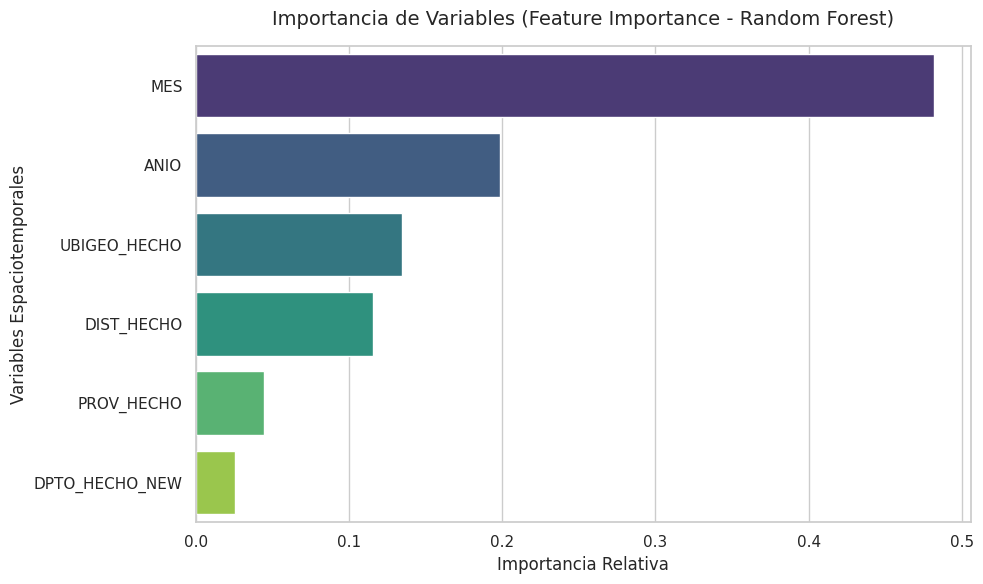

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

print(" Generando Gráficos ")

# 1. Matriz de Confusión
# Evaluamos el Baseline porque fue el que obtuvo mejor rendimiento global
cm = confusion_matrix(y_test, y_pred_base)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le_target.classes_,
            yticklabels=le_target.classes_)
plt.title('Matriz de Confusión - Modelo Base (Regresión Logística)', fontsize=14, pad=15)
plt.ylabel('Etiqueta Real (True Label)', fontsize=12)
plt.xlabel('Predicción del Modelo (Predicted Label)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 2. Interpretabilidad / Feature Importance
# Usamos Random Forest para extraer qué variable importó más en la predicción
importances = rf_modelo.feature_importances_
features = X.columns
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices], y=features[indices], palette='viridis')
plt.title('Importancia de Variables (Feature Importance - Random Forest)', fontsize=14, pad=15)
plt.xlabel('Importancia Relativa', fontsize=12)
plt.ylabel('Variables Espaciotemporales', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
!pip install gradio

In [ ]:
import os
import shutil
import yaml

print("Configurando credenciales de Kaggle desde Google Drive")
!mkdir -p ~/.kaggle
!cp /content/drive/MyDrive/kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

print("Descargando y extrayendo dataset de evidencia fotográfica")
!kaggle datasets download -d iqmansingh/guns-knives-object-detection --force
!rm -rf dataset_evidencia evidencia_clasificacion
!unzip -q guns-knives-object-detection.zip -d dataset_evidencia

# Localizar automáticamente la carpeta YOLO y su archivo data.yaml
yolo_root = None
yaml_path = None
for root, dirs, files in os.walk('dataset_evidencia'):
    if 'data.yaml' in files:
        yolo_root = root
        yaml_path = os.path.join(root, 'data.yaml')
        break

if yaml_path is None:
    raise FileNotFoundError("No se encontró data.yaml en el dataset descargado.")

with open(yaml_path, 'r') as f:
    data_cfg = yaml.safe_load(f)

raw_names = data_cfg['names']
if isinstance(raw_names, list):
    class_map = {i: str(name).strip() for i, name in enumerate(raw_names)}
else:
    class_map = {int(k): str(v).strip() for k, v in raw_names.items()}

print("INFO: Clases detectadas en el dataset:", class_map)

# Reorganizar imágenes de formato detección (YOLO) a formato clasificación (carpetas por clase)
base_dir = 'evidencia_clasificacion'
conteo_total = {}

for split in ['train', 'valid', 'test']:
    split_dir = os.path.join(yolo_root, split)
    if not os.path.exists(split_dir):
        continue

    img_paths = {}
    for r, _, files in os.walk(split_dir):
        for fname in files:
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                stem = os.path.splitext(fname)[0]
                img_paths[stem] = os.path.join(r, fname)

    conteo_total[split] = {}
    for r, _, files in os.walk(split_dir):
        for fname in files:
            if fname.lower().endswith('.txt') and fname != 'classes.txt':
                stem = os.path.splitext(fname)[0]
                if stem not in img_paths:
                    continue
                with open(os.path.join(r, fname), 'r') as lf:
                    lines = [line.strip() for line in lf if line.strip()]
                if not lines:
                    continue
                cls_id = int(lines[0].split()[0])
                cls_name = class_map.get(cls_id, f'clase_{cls_id}')
                dest_dir = os.path.join(base_dir, split, cls_name)
                os.makedirs(dest_dir, exist_ok=True)
                shutil.copy2(img_paths[stem], os.path.join(dest_dir, os.path.basename(img_paths[stem])))
                conteo_total[split][cls_name] = conteo_total[split].get(cls_name, 0) + 1

print("INFO: Imágenes organizadas por partición y clase:")
for split, counts in conteo_total.items():
    print(f"  - {split}: {counts}")

INFO: Configurando credenciales de Kaggle desde Google Drive...
INFO: Descargando y extrayendo dataset de evidencia fotográfica...
Dataset URL: https://www.kaggle.com/datasets/iqmansingh/guns-knives-object-detection
License(s): CC0-1.0
100% 136M/136M [00:09<00:00, 15.0MB/s]

INFO: Clases detectadas en el dataset: {0: 'knife', 1: 'pistol'}
INFO: Imágenes organizadas por partición y clase:
  - train: {'knife': 2342, 'pistol': 2047}
  - valid: {'pistol': 494, 'knife': 542}
  - test: {'pistol': 175, 'knife': 207}


Found 4389 files belonging to 2 classes.
Found 1036 files belonging to 2 classes.
Found 382 files belonging to 2 classes.
INFO: Clases para clasificación CNN: ['knife', 'pistol']


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,938 (16.36 MB)

 Trainable params: 4,287,938 (16.36 MB)

 Non-trainable params: 0 (0.00 B)


INFO: Iniciando entrenamiento de la CNN 2D...
Epoch 1/12
138/138 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.6931 - loss: 0.5792 - val_accuracy: 0.8031 - val_loss: 0.4322
Epoch 2/12
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8025 - loss: 0.4320 - val_accuracy: 0.8272 - val_loss: 0.3856
Epoch 3/12
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8152 - loss: 0.4021 - val_accuracy: 0.8311 - val_loss: 0.3661
Epoch 4/12
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8332 - loss: 0.3751 - val_accuracy: 0.8359 - val_loss: 0.3702
Epoch 5/12
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8350 - loss: 0.3566 - val_accuracy: 0.8330 - val_loss: 0.3734
Epoch 6/12
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8544 - loss: 0.3291 - val_accuracy: 0.8504 - val_loss: 0.3310
Epoch 7/12
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8615 - loss: 0.3196 - val_accuracy: 0.8475 - val_loss: 0.3241
Epoch 8/12
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/st

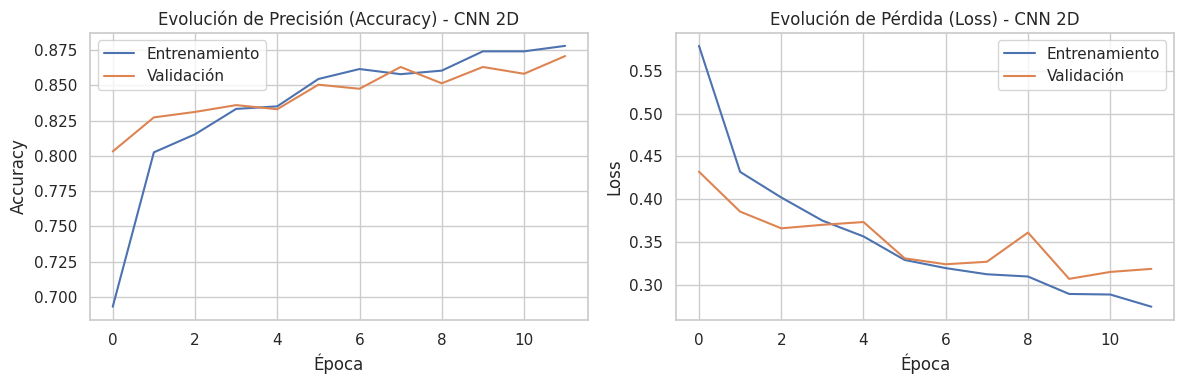

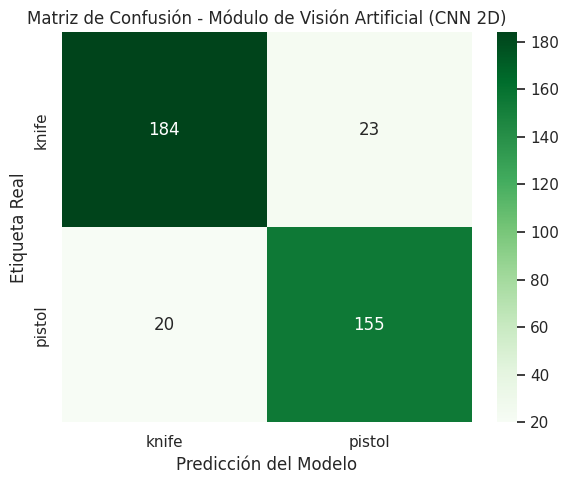

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Semilla para reproducibilidad
tf.random.set_seed(42)
np.random.seed(42)

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

#Carga de conjuntos de entrenamiento, validación y prueba
train_ds = tf.keras.utils.image_dataset_from_directory(
    'evidencia_clasificacion/train',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=42
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    'evidencia_clasificacion/valid',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=42
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    'evidencia_clasificacion/test',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

nombres_clases_cnn = train_ds.class_names
num_clases_cnn = len(nombres_clases_cnn)
print("Clases para clasificación CNN:", nombres_clases_cnn)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

#Arquitectura CNN 2D con aumento de datos y regularización
modelo_cnn = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_clases_cnn, activation='softmax')
])

modelo_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

modelo_cnn.summary()

#Entrenamiento
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

print("\nINFO: Iniciando entrenamiento de la CNN 2D...")
history = modelo_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=[early_stop]
)

#test
test_loss, test_acc = modelo_cnn.evaluate(test_ds, verbose=0)
y_true_cnn = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_pred_probs = modelo_cnn.predict(test_ds, verbose=0)
y_pred_cnn = np.argmax(y_pred_probs, axis=1)

f1_cnn = f1_score(y_true_cnn, y_pred_cnn, average='macro')
print(f"\nAccuracy Test (CNN): {test_acc:.4f}")
print(f"F1-Score Macro Test (CNN): {f1_cnn:.4f}\n")
print(classification_report(y_true_cnn, y_pred_cnn, target_names=nombres_clases_cnn))

#Gráficos de curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['accuracy'], label='Entrenamiento')
axes[0].plot(history.history['val_accuracy'], label='Validación')
axes[0].set_title('Evolución de Precisión (Accuracy) - CNN 2D')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Entrenamiento')
axes[1].plot(history.history['val_loss'], label='Validación')
axes[1].set_title('Evolución de Pérdida (Loss) - CNN 2D')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].legend()
plt.tight_layout()
plt.show()

#Matriz de Confusión de la CNN
cm_cnn = confusion_matrix(y_true_cnn, y_pred_cnn)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Greens',
            xticklabels=nombres_clases_cnn,
            yticklabels=nombres_clases_cnn)
plt.title('Matriz de Confusión - Módulo de Visión Artificial (CNN 2D)')
plt.ylabel('Etiqueta Real')
plt.xlabel('Predicción del Modelo')
plt.tight_layout()
plt.show()

In [ ]:
import gradio as gr
import pandas as pd
import cv2
import numpy as np

# Traducción de las clases aprendidas por la CNN
traducciones = {
    'gun': 'Arma de Fuego',
    'guns': 'Arma de Fuego',
    'pistol': 'Arma de Fuego',
    'knife': 'Arma Blanca',
    'knives': 'Arma Blanca'
}

def obtener_ubigeo(dpto, prov, dist):
    filtro = df[
        (df['DPTO_HECHO_NEW'] == dpto) &
        (df['PROV_HECHO'] == prov) &
        (df['DIST_HECHO'] == dist)
    ]
    if not filtro.empty:
        return int(filtro['UBIGEO_HECHO'].iloc[0])
    return 0

def prediccion_multimodal(anio, mes, departamento, provincia, distrito, imagen):
    #MÓDULO 1: PREDICCIÓN ESPACIOTEMPORAL (Regresión Logística - SIDPOL)
    try:
        dpto = str(departamento).strip().upper()
        prov = str(provincia).strip().upper()
        dist = str(distrito).strip().upper()
        ubigeo = obtener_ubigeo(dpto, prov, dist)

        input_data = pd.DataFrame({
            'ANIO': [int(anio)],
            'MES': [int(mes)],
            'DPTO_HECHO_NEW': [dpto],
            'PROV_HECHO': [prov],
            'DIST_HECHO': [dist],
            'UBIGEO_HECHO': [ubigeo]
        })

        input_encoded = input_data.copy()
        input_encoded['DPTO_HECHO_NEW'] = le_dpto.transform(input_encoded['DPTO_HECHO_NEW'])
        input_encoded['PROV_HECHO'] = le_prov.transform(input_encoded['PROV_HECHO'])
        input_encoded['DIST_HECHO'] = le_dist.transform(input_encoded['DIST_HECHO'])

        input_scaled = scaler.transform(input_encoded)
        pred_num = modelo_base.predict(input_scaled)
        delito_predicho = le_target.inverse_transform(pred_num)[0]
        salida_sidpol = f"PREDICCIÓN SIDPOL: {delito_predicho} (UBIGEO: {ubigeo})"
    except ValueError:
        salida_sidpol = "ERROR: Verifique que el Departamento, Provincia y Distrito existan en el dataset SIDPOL."
    except Exception as e:
        salida_sidpol = f"ERROR SIDPOL: {str(e)}"

    #MÓDULO 2: VISIÓN ARTIFICIAL (CNN 2D entrenada)
    if imagen is not None:
        try:
            # Asegurar 3 canales RGB (por si se sube un PNG con canal alfa)
            img_rgb = imagen[:, :, :3] if imagen.ndim == 3 and imagen.shape[2] == 4 else imagen
            img_resized = cv2.resize(img_rgb, (128, 128))
            img_array = np.expand_dims(img_resized.astype('float32'), axis=0)

            pred_cnn = modelo_cnn.predict(img_array, verbose=0)[0]
            clase_idx = int(np.argmax(pred_cnn))
            confianza = float(pred_cnn[clase_idx]) * 100
            etiqueta_raw = nombres_clases_cnn[clase_idx]
            etiqueta_es = traducciones.get(etiqueta_raw.lower(), etiqueta_raw)

            salida_cnn = f"ANÁLISIS PERICIAL: {etiqueta_es} (Confianza: {confianza:.2f}%)"
        except Exception as e:
            salida_cnn = f"ERROR CNN: {str(e)}"
    else:
        salida_cnn = "Registro sin evidencia fotográfica adjunta."

    return salida_sidpol, salida_cnn

interfaz = gr.Interface(
    fn=prediccion_multimodal,
    inputs=[
        gr.Slider(2018, 2030, value=2026, step=1, label="Año de Incidencia"),
        gr.Slider(1, 12, value=6, step=1, label="Mes de Incidencia"),
        gr.Textbox(value="LIMA METROPOLITANA", label="Departamento (Ej. LIMA METROPOLITANA)"),
        gr.Textbox(value="LIMA", label="Provincia (Ej. LIMA)"),
        gr.Textbox(value="SAN MIGUEL", label="Distrito (Ej. SAN MIGUEL)"),
        gr.Image(type="numpy", label="Registro Fotográfico de Evidencia (Opcional)")
    ],
    outputs=[
        gr.Textbox(label="Módulo 1: Inteligencia Estratégica (SIDPOL)"),
        gr.Textbox(label="Módulo 2: Visión Artificial (CNN 2D)")
    ],
    title="Sistema Híbrido de Policiamiento Predictivo y Peritaje Visual",
    description="Ingrese coordenadas espaciotemporales para clasificar el delito probable y adjunte una fotografía de evidencia para su análisis con CNN 2D."
)

interfaz.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fb4499700f62d6c24c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
